<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Hyperparameters, Grid Search and Pipelines - Solution

---

### About
How to tune models efficiently with `GridSearchCV`, and how to bundle preprocessing and modelling into one object with `Pipeline`, so that tuning is both **automatic** and **honest** (no data leakage).

### Learning Objectives
- Describe what the terms **hyperparameter**, **grid search** and **pipeline** mean.
- Apply scikit-learn's `GridSearchCV` and use its attributes (`best_params_`, `best_estimator_`, `cv_results_`).
- Describe the pitfalls of searching large hyperparameter spaces, and use `RandomizedSearchCV` instead.
- Build pipelines, including a `ColumnTransformer` for mixed numeric and categorical data.
- Explain **why** preprocessing must happen inside cross-validation.

### Notebook Guide
1. Parameters vs hyperparameters
2. Grid search (abalone data)
3. Why pipelines? A data-leakage demonstration
4. Pipelines, then pipelines + grid search (abalone, then heart disease data)
5. Large search spaces and `RandomizedSearchCV`
6. Summary, common mistakes and interview questions


> **Things to note:** the pipeline uses the k found by grid search; `sex` is used via one-hot encoding rather than being dropped; and lookout for plots and a leakage demonstration.

# Imports and Data Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, make_pipeline

plt.rcParams['figure.figsize'] = (9, 5)

# scikit-learn 1.8+ warns that LogisticRegression's `penalty` argument will change (see note below)
import warnings
warnings.filterwarnings('ignore', category=FutureWarning, message=".*'penalty' was deprecated.*")
warnings.filterwarnings('ignore', category=UserWarning, message=".*penalty is deprecated.*")

> **Version note:** from scikit-learn 1.8, `LogisticRegression(penalty=...)` is deprecated (planned removal in 1.10) in favour of `l1_ratio` (`l1_ratio=1` for Lasso, `0` for Ridge). We keep `penalty` here because it works in every current version; the line above just hides the warning. If you're on 1.10 or later, switch to `l1_ratio`.

## 1. Parameters vs hyperparameters

| | **Parameters** | **Hyperparameters** |
|---|---|---|
| Who sets them? | Learned from the data by `.fit()` | Chosen by *us* before fitting |
| Examples | Coefficients β in linear/logistic regression | `k` in k-NN, `C` in logistic regression, `alpha` in Ridge |
| How do we choose them? | The algorithm optimises them | Try several values and compare **validation** scores |

Grid search automates that last row: try every combination, score each one with cross-validation, keep the best.

## 2. The abalone data

Abalone are sea snails; their age is found by counting rings in the shell (age ≈ rings + 1.5 years), which is slow. Can we predict `rings` from easy measurements?

The file has **no header row**, so we supply the column names.

In [2]:
abalone_colnames = [
    'sex', 'length', 'diameter', 'height', 'whole_weight',
    'shucked_weight', 'viscera_weight', 'shell_weight', 'rings'
]
ab = pd.read_csv('../data/abalone.data', names=abalone_colnames)
print(ab.shape)
ab.head()

(4177, 9)


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
ab.isna().sum().sum(), ab['sex'].value_counts()   # no missing values; sex is M, F or I (infant)

(0,
 sex
 M    1528
 I    1342
 F    1307
 Name: count, dtype: int64)

### Train/test split first, always
We start with the 7 numeric measurements only (we'll add `sex` later with one-hot encoding).

In [4]:
X = ab.drop(columns=['sex', 'rings'])
y = ab['rings']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)
X_train.shape, X_test.shape

((3132, 7), (1045, 7))

# 2. Grid Search
---
Until now we've tuned hyperparameters with "sloppy loops". `GridSearchCV` does the loop for us, **with cross-validation built in**.

> **Warning sign ahead:** to keep things simple, this first version scales the data *before* the grid search. We'll see in Section 3 why that's a (small) mistake, and how pipelines fix it.

In [5]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)     # fitted on ALL training rows, including future CV validation folds
X_test_sc = sc.transform(X_test)
cross_validation_folds = 5

knn = KNeighborsRegressor()
pgrid = {'n_neighbors': np.arange(1, 202, 5)}      # 1, 6, 11, ..., 201

gs = GridSearchCV(estimator=knn, param_grid=pgrid, cv=cross_validation_folds, return_train_score=True)
gs.fit(X_train_sc, y_train)

print('candidates:', len(gs.cv_results_['params']), '| total fits:', len(gs.cv_results_['params']) * cross_validation_folds)
print('best:', gs.best_params_, '| best CV R²:', round(gs.best_score_, 3))

candidates: 41 | total fits: 205
best: {'n_neighbors': 31} | best CV R²: 0.531


In [6]:
gs.cv_results_.keys()
# gs.cv_results_.values


dict_keys(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_n_neighbors', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score', 'split0_train_score', 'split1_train_score', 'split2_train_score', 'split3_train_score', 'split4_train_score', 'mean_train_score', 'std_train_score'])

### What's inside a fitted grid search?
- `best_params_`: the winning combination.
- `best_score_`: its mean cross-validated score (R² for regressors, accuracy for classifiers, unless you set `scoring=`).
- `best_estimator_`: a copy of the model **refitted on the whole training set** with the best settings: ready to use.
- `cv_results_`: a dictionary with one row per candidate; easiest to read as a DataFrame.

In [7]:
df_gs = pd.DataFrame(gs.cv_results_)
df_gs.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   mean_fit_time       41 non-null     float64
 1   std_fit_time        41 non-null     float64
 2   mean_score_time     41 non-null     float64
 3   std_score_time      41 non-null     float64
 4   param_n_neighbors   41 non-null     int32  
 5   params              41 non-null     object 
 6   split0_test_score   41 non-null     float64
 7   split1_test_score   41 non-null     float64
 8   split2_test_score   41 non-null     float64
 9   split3_test_score   41 non-null     float64
 10  split4_test_score   41 non-null     float64
 11  mean_test_score     41 non-null     float64
 12  std_test_score      41 non-null     float64
 13  rank_test_score     41 non-null     int32  
 14  split0_train_score  41 non-null     float64
 15  split1_train_score  41 non-null     float64
 16  split2_tra

In [8]:
df_gs[['param_n_neighbors', 'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']].sort_values('rank_test_score').head(10)

,param_n_neighbors,mean_train_score,mean_test_score,std_test_score,rank_test_score
6,31,0.561871,0.531482,0.025361,1
5,26,0.567900,0.530993,0.024423,2
4,21,0.577393,0.530794,0.026958,3
3,16,0.589827,0.529824,0.023997,4
7,36,0.556208,0.529241,0.023663,5
8,41,0.551977,0.526561,0.023059,6
9,46,0.547717,0.525300,0.024109,7
10,51,0.542896,0.522846,0.024412,8
2,11,0.608078,0.521188,0.023288,9
11,56,0.538731,0.519622,0.024444,10


### Plot: the bias-variance trade-off, in one picture
`return_train_score=True` lets us plot **training** and **validation** R² together:
- small k → the model memorises the training data (train R² high, validation lower): **overfitting / high variance**;
- large k → predictions become averages of huge neighbourhoods: **underfitting / high bias**;
- the best k sits where validation R² peaks.

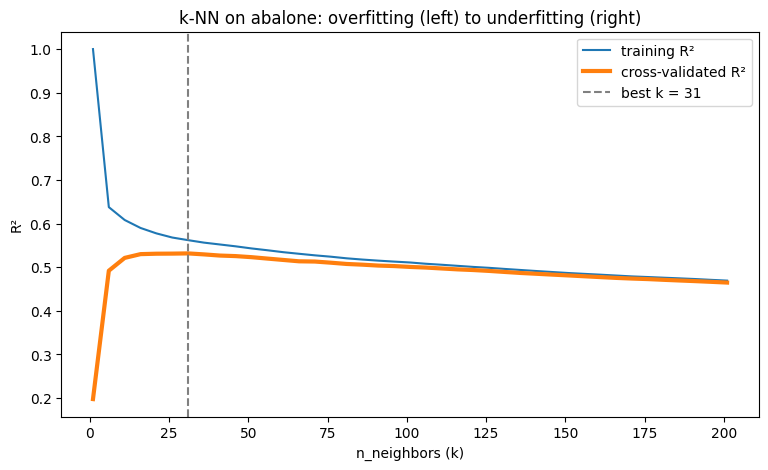

In [9]:
best_k = gs.best_params_['n_neighbors'] # the winning combination
plt.plot(df_gs['param_n_neighbors'], df_gs['mean_train_score'], label='training R²')
plt.plot(df_gs['param_n_neighbors'], df_gs['mean_test_score'], label='cross-validated R²', lw=3)
plt.axvline(best_k, color='grey', ls='--', label=f'best k = {best_k}')
plt.xlabel('n_neighbors (k)'); plt.ylabel('R²'); plt.title('k-NN on abalone: overfitting (left) to underfitting (right)')
plt.legend();

**Let's check our understanding:**

<details><summary>
 Why is training R² equal to 1.0 at k = 1?
</summary>

Each training point is its own nearest neighbour, so the model predicts it perfectly. </details>

**Edge check:** 
<details><summary>
Is the best k at the edge of the grid?
</summary>
If it were (e.g. k = 201), the true best might lie outside the range, and you'd extend the grid. </details>

## **To the Slides!**

# 3. Why pipelines? A data-leakage demonstration
---
**Data leakage** = information from the validation (or test) data sneaking into training. It makes scores look better than they'll really be.

In Section 2 the scaler saw every training row before cross-validation, so each validation fold had already influenced the scaling. For scaling the effect is tiny. For other preprocessing steps it can be enormous. Here's a dramatic example:

- 100 rows of **pure random noise**: 5,000 random features and random 0/1 labels. There is *nothing* to learn; honest accuracy should be about 50%.
- We pick the 20 features most correlated with the labels, then cross-validate a model on them.

In [10]:
from sklearn.feature_selection import SelectKBest, f_classif

rng = np.random.default_rng(42)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, 100)

# WRONG: feature selection sees ALL rows (including every future validation fold)
X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=cross_validation_folds).mean()

# RIGHT: selection happens inside each training fold, via a pipeline
pipe_noise = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(pipe_noise, X_noise, y_noise, cv=cross_validation_folds).mean()

print(f'leaky CV accuracy:  {leaky:.2f}   <- looks like a great model... on random noise!')
print(f'honest CV accuracy: {honest:.2f}   <- about chance, which is the truth')

leaky CV accuracy:  0.89   <- looks like a great model... on random noise!
honest CV accuracy: 0.52   <- about chance, which is the truth


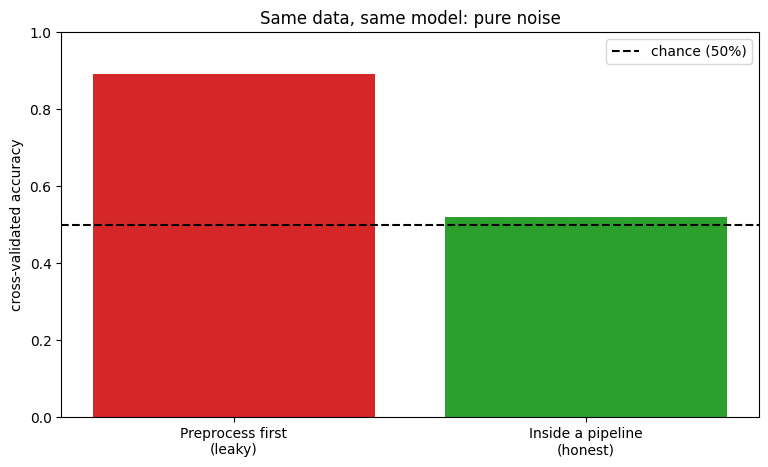

In [11]:
plt.bar(['Preprocess first\n(leaky)', 'Inside a pipeline\n(honest)'], [leaky, honest], color=['tab:red', 'tab:green'])
plt.axhline(0.5, color='black', ls='--', label='chance (50%)')
plt.ylim(0, 1); plt.ylabel('cross-validated accuracy'); plt.title('Same data, same model: pure noise')
plt.legend();

**The lesson:** anything that *learns from data* (scaling, imputing, encoding, selecting features, resampling) must be fitted **inside** each training fold. A `Pipeline` does exactly that automatically.

# 4. Pipelines
---
A `Pipeline` chains steps into one object that behaves like a single model:

```
raw X  ──►  StandardScaler  ──►  KNeighborsRegressor  ──►  prediction
            (fit on training data only)
```

- `pipe.fit(X_train, y_train)`: fits the scaler on X_train, transforms it, then fits the model.
- `pipe.predict(X_test)` / `pipe.score(X_test, y_test)`: transforms X_test with the **already-fitted** scaler, then predicts.
- Inside `GridSearchCV`, the whole pipeline is refitted on each training fold: no leakage.

We fit on the **unscaled** data; the pipeline does the scaling. We use the k that grid search found.

In [12]:
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=best_k))
])
pipe.fit(X_train, y_train)
print(f'test R²: {round(pipe.score(X_test, y_test), 3)} for k = {best_k}')

test R²: 0.499 for k = 31


### Pipeline + grid search: the leak-free version of Section 2
Hyperparameters inside a pipeline are named **`stepname__parameter`** (two underscores).

In [13]:
pipe = Pipeline([('sc', StandardScaler()), ('knn', KNeighborsRegressor())])
gs_pipe = GridSearchCV(pipe, {'knn__n_neighbors': np.arange(1, 202, 5)}, cv=cross_validation_folds)
gs_pipe.fit(X_train, y_train)                      # raw data in; scaling happens inside each fold
print('leak-free best:', gs_pipe.best_params_, '| CV R²:', round(gs_pipe.best_score_, 3),
      '| test R²:', round(gs_pipe.score(X_test, y_test), 3))
print('leaky version for comparison: CV R²', round(gs.best_score_, 3))

leak-free best: {'knn__n_neighbors': 31} | CV R²: 0.532 | test R²: 0.499
leaky version for comparison: CV R² 0.531


Same answer here (scaling leaks very little), but now the process is correct, and it would stay correct with any preprocessing step.

### Mixed data types: `ColumnTransformer`
Initially the feature `sex` was dropped "because we're doing k-NN". It doesn't need to be: one-hot encode it and scale the numeric columns, all inside the pipeline.

In [14]:
X_all = ab.drop(columns='rings')
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_all, y, random_state=2022)

numeric = X_all.columns.drop('sex')
prep = ColumnTransformer([
    ('num', StandardScaler(), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['sex'])
])
pipe_ct = Pipeline([('prep', prep), ('knn', KNeighborsRegressor())])
gs_ct = GridSearchCV(pipe_ct, {'knn__n_neighbors': np.arange(1, 202, 5)}, cv=cross_validation_folds).fit(Xa_train, ya_train)
print('with sex:', gs_ct.best_params_, '| CV R²:', round(gs_ct.best_score_, 3), '| test R²:', round(gs_ct.score(Xa_test, ya_test), 3))

with sex: {'knn__n_neighbors': 16} | CV R²: 0.525 | test R²: 0.49


Including `sex` doesn't help here (R² is about the same). That's a legitimate finding, but the reason to drop a feature should be evidence like this, not "the algorithm can't use it".

# Pipelines + Grid Search, all together, on new data
We'll use data on heart disease from a study of men in the Western Cape, South Africa ([description](https://hastie.su.domains/ElemStatLearn/datasets/SAheart.info.txt)). Target: `chd` (coronary heart disease, 1 = yes).

In [15]:
heart = pd.read_csv('../data/SAheart.data')
heart['famhist'] = (heart['famhist'] == 'Present') * 1      # family history: text -> 0/1
X = heart.drop(columns=['row.names', 'chd'])
y = heart['chd']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)
print(X_train.shape, '| share with heart disease:', round(y.mean(), 3), '| null accuracy:', round(1 - y.mean(), 3))

(346, 9) | share with heart disease: 0.346 | null accuracy: 0.654


We tune **two** hyperparameters at once: the type of regularisation (`l1` = Lasso, `l2` = Ridge) and its strength `C` (smaller C = stronger regularisation). Grid size = 2 × 100 = 200 combinations × 5 folds = **1,000 fits**.

> Warning! You could accidentally make too many combinations and your search could take an extremely long time. Start small. (Do we really need 100 values of C? The random search in Section 5 suggests not.)

In [16]:
pipe = Pipeline([
    ('sc', StandardScaler()),
    ('lr', LogisticRegression(solver='liblinear', random_state=42))   # seed: liblinear's L1 solver is randomised
])
pgrid = {
    'lr__penalty': ['l1', 'l2'],
    'lr__C': np.logspace(-2, 0, 100)       # 0.01 to 1, evenly spaced on a log scale
}
gs = GridSearchCV(pipe, param_grid=pgrid, cv=cross_validation_folds)
%time gs.fit(X_train, y_train)
print('best:', gs.best_params_, '| CV accuracy:', round(gs.best_score_, 3), '| test accuracy:', round(gs.score(X_test, y_test), 3))

CPU times: total: 4.7 s
Wall time: 4.76 s
best: {'lr__C': 0.12328467394420665, 'lr__penalty': 'l1'} | CV accuracy: 0.743 | test accuracy: 0.716


### Plot: comparing two hyperparameters at once
A log-scaled x-axis makes the C values evenly spaced. The dashed line is the **null model** (always predict "no heart disease"): any useful model must beat it.

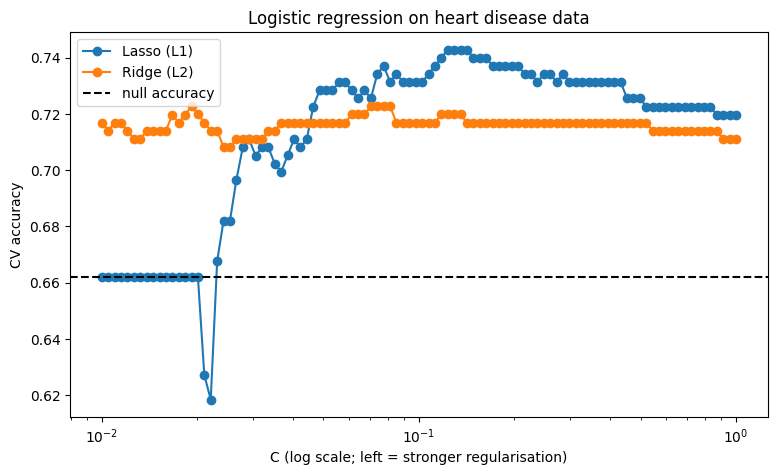

In [17]:
df_gs = pd.DataFrame(gs.cv_results_)
for penalty, label in [('l1', 'Lasso (L1)'), ('l2', 'Ridge (L2)')]:
    rows = df_gs[df_gs['param_lr__penalty'] == penalty]
    plt.plot(rows['param_lr__C'], rows['mean_test_score'], marker='o', label=label)
plt.axhline(1 - y_train.mean(), color='black', ls='--', label='null accuracy')
plt.xscale('log'); plt.xlabel('C (log scale; left = stronger regularisation)'); plt.ylabel('CV accuracy')
plt.title('Logistic regression on heart disease data'); plt.legend();

**Reading the plot:** with very strong regularisation (left), Lasso shrinks every coefficient to zero and the model just predicts the majority class: its accuracy equals the null model. As C grows, the model is allowed to use the features and accuracy improves, then levels off.

### Which features did the best model keep?

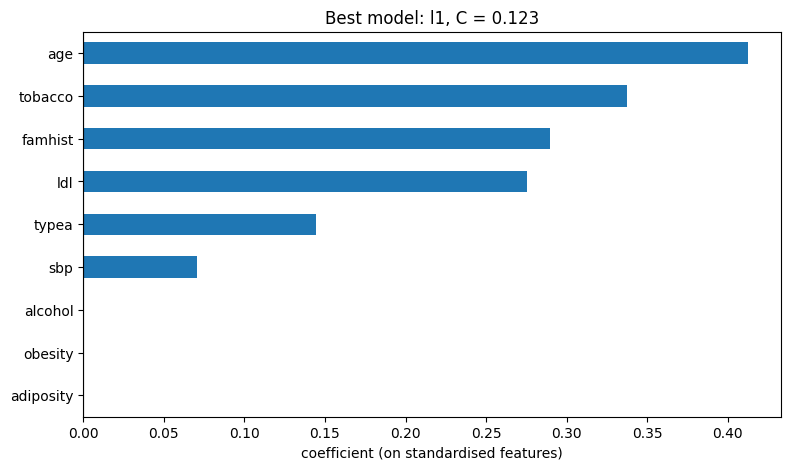

In [18]:
best_lr = gs.best_estimator_.named_steps['lr']
coefs = pd.Series(best_lr.coef_[0], index=X.columns).sort_values()
coefs.plot(kind='barh', color=['tab:red' if c < 0 else 'tab:blue' for c in coefs])
plt.axvline(0, color='black'); plt.xlabel('coefficient (on standardised features)')
plt.title(f"Best model: {gs.best_params_['lr__penalty']}, C = {gs.best_params_['lr__C']:.3f}");

Coefficients are on **standardised** features, so their sizes are comparable. If the best model is Lasso, any coefficient at exactly 0 has been dropped.

# 5. A word of caution on grid searching
---
Grid search tries **every combination**, so the number of fits multiplies quickly:

In [19]:
from sklearn.model_selection import ParameterGrid
big_grid = {
    'n_neighbors': range(1, 151),
    'weights': ['uniform', 'distance'],
    'p': [1, 2],
    'leaf_size': [10, 20, 30, 40, 50],
}
n = len(ParameterGrid(big_grid))
print(f'{n:,} combinations x 5 folds = {n * 5:,} model fits')

3,000 combinations x 5 folds = 15,000 model fits


## Alternative: `RandomizedSearchCV`
**Random search** tries a fixed number (`n_iter`) of random combinations, drawn from lists or from distributions. It usually finds a near-best result for a fraction of the cost, especially when only one or two hyperparameters really matter.

(The original notebook's empty `RandomizedSearchCV()` cell raises an error: it needs an estimator and the distributions to sample from.)

In [20]:
from scipy.stats import loguniform

rs = RandomizedSearchCV(
    pipe,
    param_distributions={'lr__penalty': ['l1', 'l2'], 'lr__C': loguniform(1e-2, 1e0)},
    n_iter=15, cv=cross_validation_folds, random_state=42
)
rs.fit(X_train, y_train)
print('random search:', rs.best_params_, '| CV accuracy:', round(rs.best_score_, 3), '| fits:', 15 * 5)
print('grid search:  ', gs.best_params_, '| CV accuracy:', round(gs.best_score_, 3), '| fits:', len(df_gs) * 5)

random search: {'lr__C': 0.15751320499779725, 'lr__penalty': 'l1'} | CV accuracy: 0.74 | fits: 75
grid search:   {'lr__C': 0.12328467394420665, 'lr__penalty': 'l1'} | CV accuracy: 0.743 | fits: 1000


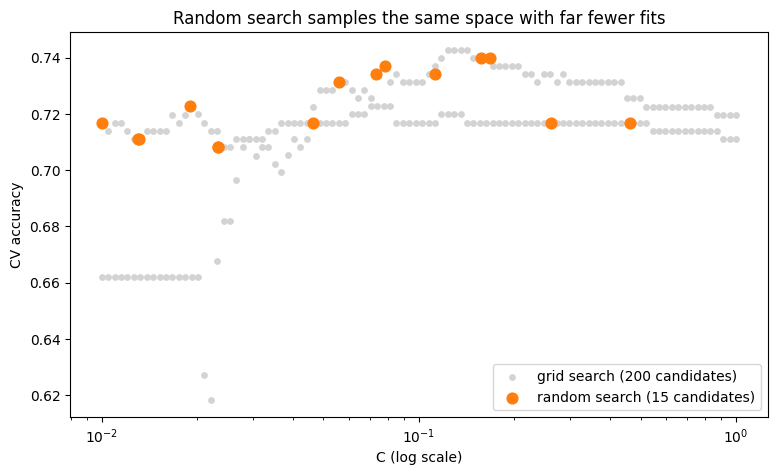

In [21]:
df_rs = pd.DataFrame(rs.cv_results_)
plt.scatter(df_gs['param_lr__C'], df_gs['mean_test_score'], s=15, color='lightgrey', label='grid search (200 candidates)')
plt.scatter(df_rs['param_lr__C'], df_rs['mean_test_score'], s=60, color='tab:orange', label='random search (15 candidates)')
plt.xscale('log'); plt.xlabel('C (log scale)'); plt.ylabel('CV accuracy'); plt.legend()
plt.title('Random search samples the same space with far fewer fits');

# 6. Summary
---
### Key ideas
- **Hyperparameters** are set by you; **parameters** are learned by `.fit()`.
- **`GridSearchCV`** tries every combination with cross-validation; `best_estimator_` is refitted and ready to use.
- **Pipelines** bundle preprocessing + model so that every learned step is fitted on training folds only: no leakage.
- Name pipeline hyperparameters `step__parameter`.
- For big search spaces, use **`RandomizedSearchCV`** and log-spaced ranges.

### Common mistakes checklist
- [ ] Preprocessing (scaling, encoding, selection) done **before** the grid search instead of inside a pipeline.
- [ ] Using the **test set** to choose hyperparameters (it should only be used once, at the end).
- [ ] Best value at the **edge** of the grid (extend the range).
- [ ] A grid so large it takes hours: start coarse, then refine.
- [ ] Forgetting the **baseline**: always compare with the null model.

### Interview questions
<details><summary>What is the difference between hyperparameters and statistical parameters?</summary>

- Statistical parameters are quantities a model learns from the data, e.g. β₀ and β₁ in a linear model.
- Hyperparameters can't be learned by fitting, but affect the fit, e.g. k in k-NN or C in logistic regression. We choose them with validation.
</details>

<details><summary>Why should scaling go inside a pipeline when you cross-validate?</summary>

Because the scaler learns means and standard deviations. Fitting it on all the data lets each validation fold influence the training, which makes validation scores over-optimistic (see the noise demonstration in Section 3).
</details>